In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("ForgeMind Data Exploration")
print("=" * 40)

ForgeMind Data Exploration


In [2]:
from pathlib import Path

# Project root
PROJECT_ROOT = Path.cwd().parent

# Raw C-MAPSS dataset
DATA_DIR = PROJECT_ROOT / "data" / "raw" / "cmapss"

TRAIN_FILE = DATA_DIR / "train_FD001.txt"

print("Project root:", PROJECT_ROOT)
print("Training file:", TRAIN_FILE)
print("File exists:", TRAIN_FILE.exists())

Project root: /home/ajinkyasingh/Documents/forgemind
Training file: /home/ajinkyasingh/Documents/forgemind/data/raw/cmapss/train_FD001.txt
File exists: True


In [3]:
train_df = pd.read_csv(
    TRAIN_FILE,
    sep=r"\s+",
    header=None
)

print("Dataset loaded successfully!")
print("Shape:", train_df.shape)

Dataset loaded successfully!
Shape: (20631, 26)


In [4]:
columns = [
    "unit_id",
    "cycle",
    "op_setting_1",
    "op_setting_2",
    "op_setting_3"
]

sensor_columns = [
    f"sensor_{i}"
    for i in range(1, 22)
]

columns.extend(sensor_columns)

train_df.columns = columns

print(train_df.columns.tolist())

['unit_id', 'cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


In [5]:
train_df.head()

,unit_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [6]:
train_df.tail()

,unit_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,519.49,2388.26,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,519.68,2388.22,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,520.01,2388.24,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,519.67,2388.23,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640
20630,100,200,-0.0032,-0.0005,100.0,518.67,643.85,1600.38,1432.14,14.62,...,519.30,2388.26,8137.33,8.5036,0.03,396,2388,100.0,38.37,23.0522


In [7]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   unit_id       20631 non-null  int64  
 1   cycle         20631 non-null  int64  
 2   op_setting_1  20631 non-null  float64
 3   op_setting_2  20631 non-null  float64
 4   op_setting_3  20631 non-null  float64
 5   sensor_1      20631 non-null  float64
 6   sensor_2      20631 non-null  float64
 7   sensor_3      20631 non-null  float64
 8   sensor_4      20631 non-null  float64
 9   sensor_5      20631 non-null  float64
 10  sensor_6      20631 non-null  float64
 11  sensor_7      20631 non-null  float64
 12  sensor_8      20631 non-null  float64
 13  sensor_9      20631 non-null  float64
 14  sensor_10     20631 non-null  float64
 15  sensor_11     20631 non-null  float64
 16  sensor_12     20631 non-null  float64
 17  sensor_13     20631 non-null  float64
 18  sensor_14     20631 non-null  float64

In [8]:
number_of_engines = train_df["unit_id"].nunique()

print("Number of engines:", number_of_engines)

Number of engines: 100


In [9]:
engine_lifetimes = train_df.groupby("unit_id")["cycle"].max()

engine_lifetimes.head(10)

unit_id
1     192
2     287
3     179
4     189
5     269
6     188
7     259
8     150
9     201
10    222
Name: cycle, dtype: int64

In [10]:
print("Shortest engine life:",
      engine_lifetimes.min())

print("Longest engine life:",
      engine_lifetimes.max())

print("Average engine life:",
      engine_lifetimes.mean())

Shortest engine life: 128
Longest engine life: 362
Average engine life: 206.31


In [11]:
missing_values = train_df.isnull().sum()

missing_values[missing_values > 0]

Series([], dtype: int64)

In [12]:
missing_values = train_df.isnull().sum()

missing_values[missing_values > 0]


Series([], dtype: int64)

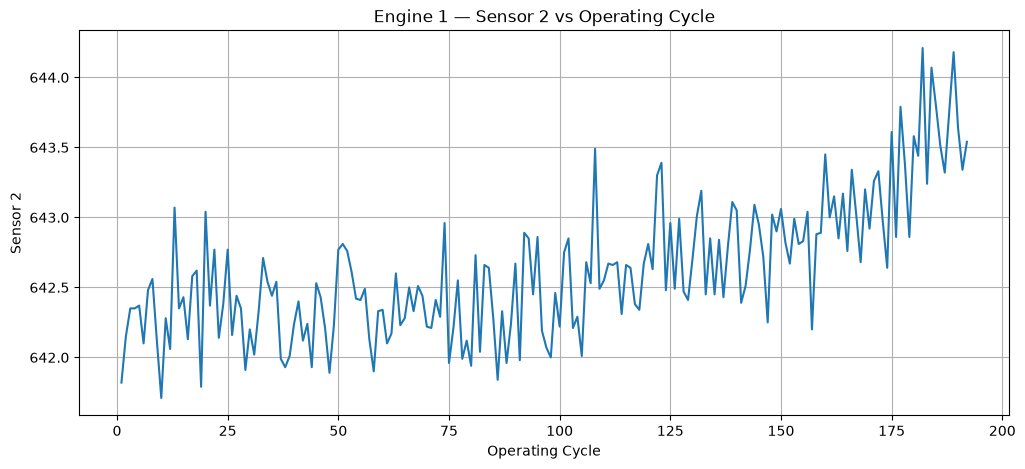

In [13]:
engine_id = 1

engine_1 = train_df[
    train_df["unit_id"] == engine_id
]

plt.figure(figsize=(12, 5))

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_2"]
)

plt.xlabel("Operating Cycle")
plt.ylabel("Sensor 2")
plt.title("Engine 1 — Sensor 2 vs Operating Cycle")

plt.grid(True)
plt.show()

In [14]:
max_cycles = (
    train_df
    .groupby("unit_id")["cycle"]
    .max()
)

max_cycles.head()

unit_id
1    192
2    287
3    179
4    189
5    269
Name: cycle, dtype: int64

In [15]:
train_df["max_cycle"] = train_df["unit_id"].map(max_cycles)

In [16]:
train_df[
    ["unit_id", "cycle", "max_cycle"]
].head(10)

,unit_id,cycle,max_cycle
0,1,1,192
1,1,2,192
2,1,3,192
3,1,4,192
4,1,5,192
5,1,6,192
6,1,7,192
7,1,8,192
8,1,9,192
9,1,10,192


In [17]:
train_df["RUL"] = (
    train_df["max_cycle"] - train_df["cycle"]
)

In [18]:
train_df[
    ["unit_id", "cycle", "max_cycle", "RUL"]
].head(10)

,unit_id,cycle,max_cycle,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


In [19]:
train_df[
    train_df["unit_id"] == 1
].tail()

,unit_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,max_cycle,RUL
187,1,188,-0.0067,0.0003,100.0,518.67,643.75,1602.38,1422.78,14.62,...,8117.69,8.5207,0.03,396,2388,100.0,38.51,22.9588,192,4
188,1,189,-0.0006,0.0002,100.0,518.67,644.18,1596.17,1428.01,14.62,...,8117.51,8.5183,0.03,395,2388,100.0,38.48,23.1127,192,3
189,1,190,-0.0027,0.0001,100.0,518.67,643.64,1599.22,1425.95,14.62,...,8112.58,8.5223,0.03,398,2388,100.0,38.49,23.0675,192,2
190,1,191,-0.0000,-0.0004,100.0,518.67,643.34,1602.36,1425.77,14.62,...,8114.61,8.5174,0.03,394,2388,100.0,38.45,23.1295,192,1
191,1,192,0.0009,-0.0000,100.0,518.67,643.54,1601.41,1427.20,14.62,...,8110.93,8.5113,0.03,396,2388,100.0,38.48,22.9649,192,0


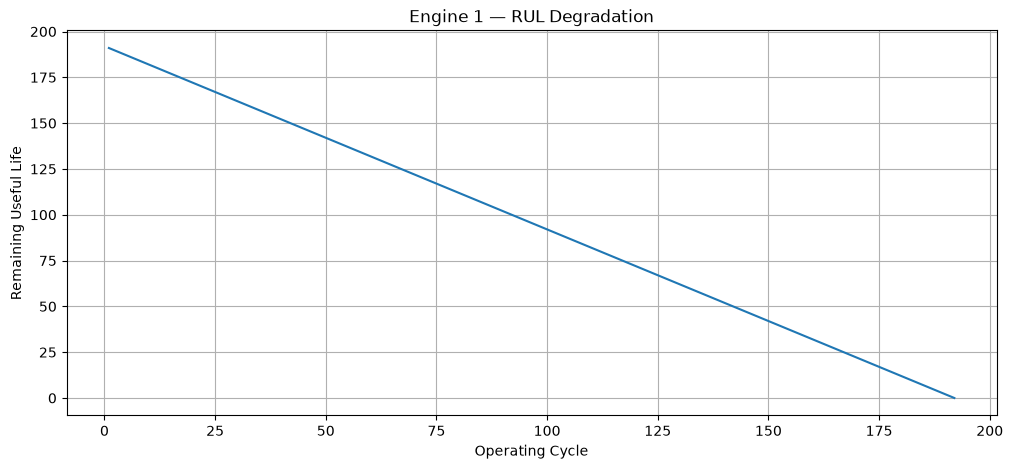

In [20]:
engine_1 = train_df[
    train_df["unit_id"] == 1
]

plt.figure(figsize=(12, 5))

plt.plot(
    engine_1["cycle"],
    engine_1["RUL"]
)

plt.xlabel("Operating Cycle")
plt.ylabel("Remaining Useful Life")
plt.title("Engine 1 — RUL Degradation")

plt.grid(True)
plt.show()

In [21]:
sensor_columns = [
    f"sensor_{i}"
    for i in range(1, 22)
]

correlations = (
    train_df[sensor_columns + ["RUL"]]
    .corr()["RUL"]
    .drop("RUL")
    .sort_values()
)

correlations

sensor_11   -0.696228
sensor_4    -0.678948
sensor_15   -0.642667
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
sensor_20    0.629428
sensor_21    0.635662
sensor_7     0.657223
sensor_12    0.671983
sensor_1          NaN
sensor_5          NaN
sensor_10         NaN
sensor_16         NaN
sensor_18         NaN
sensor_19         NaN
Name: RUL, dtype: float64

In [22]:
sensor_columns = [
    f"sensor_{i}"
    for i in range(1, 22)
]

correlations = (
    train_df[sensor_columns + ["RUL"]]
    .corr()["RUL"]
    .drop("RUL")
    .sort_values()
)

correlations

sensor_11   -0.696228
sensor_4    -0.678948
sensor_15   -0.642667
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
sensor_20    0.629428
sensor_21    0.635662
sensor_7     0.657223
sensor_12    0.671983
sensor_1          NaN
sensor_5          NaN
sensor_10         NaN
sensor_16         NaN
sensor_18         NaN
sensor_19         NaN
Name: RUL, dtype: float64

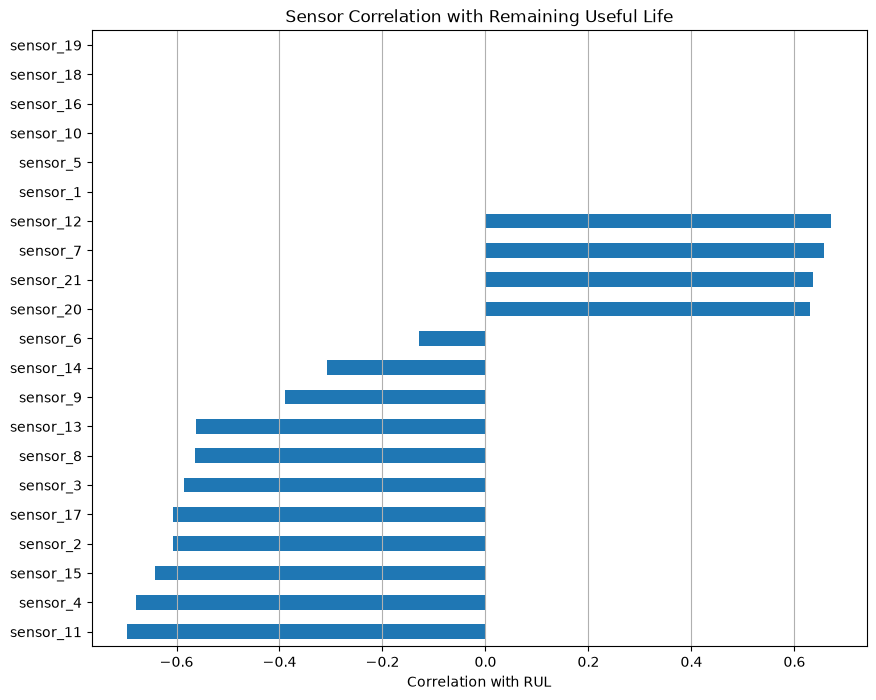

In [23]:
plt.figure(figsize=(10, 8))

correlations.sort_values().plot(
    kind="barh"
)

plt.xlabel("Correlation with RUL")
plt.title("Sensor Correlation with Remaining Useful Life")

plt.grid(axis="x")

plt.show()

In [24]:
from pathlib import Path

processed_dir = PROJECT_ROOT / "data" / "processed"

processed_dir.mkdir(
    parents=True,
    exist_ok=True
)

In [25]:
processed_file = (
    processed_dir /
    "train_FD001_with_rul.csv"
)

train_df.to_csv(
    processed_file,
    index=False
)

print("Saved:", processed_file)

Saved: /home/ajinkyasingh/Documents/forgemind/data/processed/train_FD001_with_rul.csv
